In [ ]:
# Cell 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
# Cell 2: Load Dataset
data = pd.read_csv("ML-Dataset.csv")
print("Dataset Preview:")
display(data.head())

print("\nColumns:", data.columns.tolist())

Dataset Preview:


,RegionName,CountryName,State,City,PostalCode,WarehouseAddress,WarehouseName,EmployeeName,EmployeeEmail,EmployeePhone,...,CustomerName,CustomerAddress,CustomerCreditLimit,CustomerEmail,CustomerPhone,Status,OrderDate,OrderItemQuantity,PerUnitPrice,TotalItemQuantity
0,South America,United States of America,Texas,Southlake,26192,2014 Jabberwocky Rd,Southlake Texas,Summer Payne,summer.payne@example.com,5151238181,...,Flor Stone,2904 S Salina St,5000,flor.stone@raytheon.com,13171234104,Shipped,17-Nov-16,132,469.99,122
1,South America,United States of America,Texas,Southlake,26192,2014 Jabberwocky Rd,Southlake Texas,Rose Stephens,rose.stephens@example.com,5151238080,...,Lavera Emerson,"5344 Haverford Ave, Philadelphia",5000,lavera.emerson@plainsallamerican.com,13171234111,Shipped,20-Feb-17,124,519.99,123
2,South America,United States of America,Texas,Southlake,26192,2014 Jabberwocky Rd,Southlake Texas,Annabelle Dunn,annabelle.dunn@example.com,5151234444,...,Fern Head,"1795 Wu Meng, Muang Chonburi",1200,fern.head@usfoods.com,18121234115,Canceled,03-Jan-17,92,800.74,123
3,South America,United States of America,Texas,Southlake,26192,2014 Jabberwocky Rd,Southlake Texas,Tommy Bailey,tommy.bailey@example.com,5151234567,...,Shyla Ortiz,"Walpurgisstr 69, Munich",2400,shyla.ortiz@abbvie.com,13171234126,Pending,15-Oct-17,128,849.99,124
4,South America,United States of America,Texas,Southlake,26192,2014 Jabberwocky Rd,Southlake Texas,Blake Cooper,blake.cooper@example.com,5151234569,...,Jeni Levy,"Via Frenzy 6903, Roma",1200,jeni.levy@centene.com,18121214129,Shipped,09-Apr-17,106,109.99,125



Columns: ['RegionName', 'CountryName', 'State', 'City', 'PostalCode', 'WarehouseAddress', 'WarehouseName', 'EmployeeName', 'EmployeeEmail', 'EmployeePhone', 'EmployeeHireDate', 'EmployeeJobTitle', 'CategoryName', 'ProductName', 'ProductDescription', 'ProductStandardCost', 'Profit', 'ProductListPrice', 'CustomerName', 'CustomerAddress', 'CustomerCreditLimit', 'CustomerEmail', 'CustomerPhone', 'Status', 'OrderDate', 'OrderItemQuantity', 'PerUnitPrice', 'TotalItemQuantity']


Missing values per column:
RegionName             0
CountryName            0
State                  0
City                   0
PostalCode             0
WarehouseAddress       0
WarehouseName          0
EmployeeName           0
EmployeeEmail          0
EmployeePhone          0
EmployeeHireDate       0
EmployeeJobTitle       0
CategoryName           0
ProductName            0
ProductDescription     0
ProductStandardCost    0
Profit                 0
ProductListPrice       0
CustomerName           0
CustomerAddress        0
CustomerCreditLimit    0
CustomerEmail          0
CustomerPhone          0
Status                 0
OrderDate              0
OrderItemQuantity      0
PerUnitPrice           0
TotalItemQuantity      0
dtype: int64

Summary statistics:


,EmployeePhone,ProductStandardCost,Profit,ProductListPrice,CustomerCreditLimit,CustomerPhone,OrderItemQuantity,PerUnitPrice,TotalItemQuantity
count,4.000000e+02,400.000000,400.000000,400.000000,400.000000,4.000000e+02,400.000000,400.000000,400.000000
mean,1.300551e+12,1812.654525,189.743700,2002.398800,2033.617500,6.422348e+10,89.240000,839.253100,123.695000
std,3.546655e+12,4297.988742,254.318871,4432.591249,1534.488065,1.871854e+11,34.064253,706.449917,67.438876
min,1.856490e+07,12.630000,0.000000,15.550000,100.000000,4.538500e+04,32.000000,16.990000,0.000000
25%,9.716165e+08,414.160000,59.972500,502.982500,700.000000,3.545837e+09,61.000000,352.982500,92.750000
50%,1.168870e+10,698.320000,134.200000,849.990000,1500.000000,9.800588e+09,85.500000,686.990000,123.000000
75%,2.651186e+10,1671.950000,229.520000,1999.890000,3500.000000,1.812122e+10,118.000000,1055.990000,178.000000
max,1.144164e+13,75410.000000,2770.000000,78180.000000,5000.000000,9.138593e+11,157.000000,4139.000000,353.000000


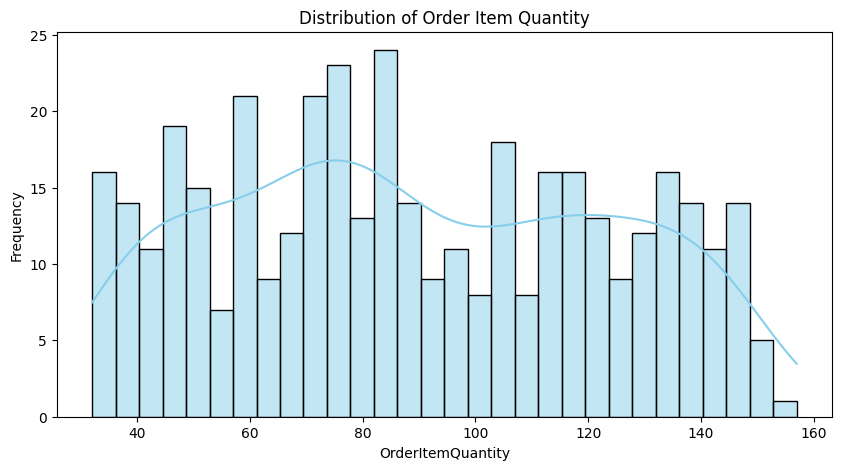

In [ ]:
# Cell 3: Dataset Exploration
# Check for missing values
print("Missing values per column:")
print(data.isnull().sum())

# Basic statistics
print("\nSummary statistics:")
display(data.describe())

# Histogram of order quantities
plt.figure(figsize=(10,5))
sns.histplot(data['OrderItemQuantity'], bins=30, kde=True, color='skyblue')
plt.title("Distribution of Order Item Quantity")
plt.xlabel("OrderItemQuantity")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# Cell 4: Preprocess Dataset
# Convert OrderDate to datetime
data['OrderDate'] = pd.to_datetime(data['OrderDate'], errors='coerce')

# Aggregate daily demand
daily_demand = data.groupby('OrderDate')['OrderItemQuantity'].sum().reset_index()
daily_demand.rename(columns={'OrderItemQuantity': 'demand'}, inplace=True)

print("Daily demand preview:")
display(daily_demand.head())

# Extract demand series
demand_series = daily_demand['demand'].values

Daily demand preview:


/tmp/ipython-input-1705642106.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data['OrderDate'] = pd.to_datetime(data['OrderDate'], errors='coerce')


,OrderDate,demand
0,2013-06-21,567
1,2015-04-09,507
2,2015-04-26,198
3,2015-05-02,275
4,2015-05-03,315


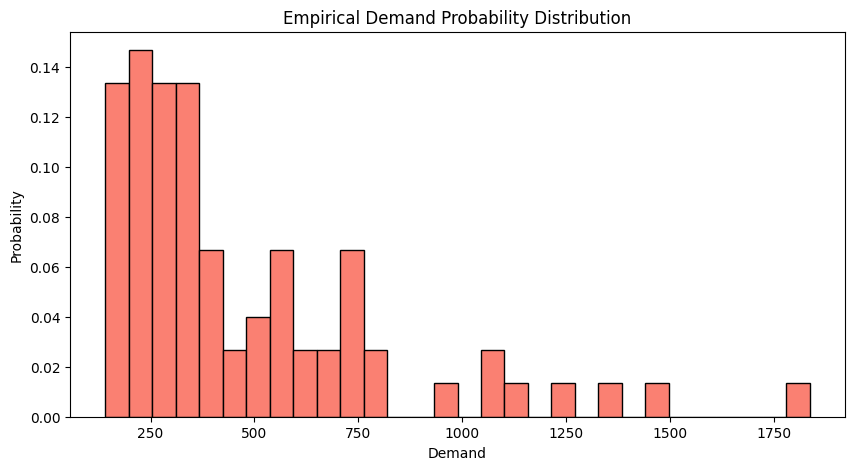

In [ ]:
# Choose number of bins, e.g., 30
num_bins = 30

# Compute histogram
demand_hist, bin_edges = np.histogram(demand_series, bins=num_bins, density=True)
demand_prob = demand_hist / demand_hist.sum()

# Plot
plt.figure(figsize=(10,5))
plt.bar(bin_edges[:-1], demand_prob, width=np.diff(bin_edges), color='salmon', edgecolor='black', align='edge')
plt.title("Empirical Demand Probability Distribution")
plt.xlabel("Demand")
plt.ylabel("Probability")
plt.show()

In [ ]:
# ============================
# Step Function
# ============================
def mdp_step(inventory, order, demand, ordering_cost=1, holding_cost=0.5, shortage_cost=2):
    """
    Simulates one period of the inventory system.
    Returns next inventory and reward (negative cost).
    """
    # Update inventory
    next_inventory = inventory + order - demand

    # Costs
    actual_holding = max(next_inventory, 0)
    shortage = max(-next_inventory, 0)
    total_cost = (order * ordering_cost) + (actual_holding * holding_cost) + (shortage * shortage_cost)

    # Inventory cannot be negative
    next_inventory = max(next_inventory, 0)

    # Reward = -cost
    reward = -total_cost

    return next_inventory, reward

In [ ]:
# ============================
# Simulation Function
# ============================
def simulate_inventory(mdp, demand_series, initial_inventory=50, periods=100):
    """
    Simulates inventory system over multiple periods using a policy.
    """
    inventory = initial_inventory
    inventory_history, order_history, demand_history = [], [], []
    total_cost = 0

    for t in range(periods):
        demand = demand_series[t % len(demand_series)]

        # Determine action from policy
        inventory_state = min(inventory, len(mdp.policy) - 1)
        order = mdp.policy[inventory_state]

        # Apply step function
        next_inventory, reward = mdp.step(inventory, order, demand)

        # Record histories
        inventory_history.append(inventory)
        order_history.append(order)
        demand_history.append(demand)
        total_cost += -reward  # Convert reward to positive cost

        # Update inventory
        inventory = next_inventory

    return inventory_history, order_history, demand_history, total_cost


In [ ]:
# ============================
# MDP Class
# ============================
class InventoryMDP:
    def __init__(self, max_inventory, ordering_cost=1, holding_cost=0.5, shortage_cost=2):
        self.max_inventory = max_inventory
        self.ordering_cost = ordering_cost
        self.holding_cost = holding_cost
        self.shortage_cost = shortage_cost
        self.policy = np.zeros(max_inventory + 1, dtype=int)  # Placeholder for policy
        self.step = None  # Will assign later

In [ ]:
# ============================
# Define Policies
# ============================
mdp = InventoryMDP(max_inventory=100)

# Naive Policy: always order 20 units
mdp.policy_naive = np.full(mdp.max_inventory + 1, 20)

# "Optimal" Policy: orders more when inventory < 50
mdp.policy_optimal = np.array([50 - i if i < 50 else 0 for i in range(mdp.max_inventory + 1)])

In [ ]:
# ============================
# Assign Step Function
# ============================
mdp.step = lambda inv, ord, dem: mdp_step(inv, ord, dem,
                                          ordering_cost=mdp.ordering_cost,
                                          holding_cost=mdp.holding_cost,
                                          shortage_cost=mdp.shortage_cost)

In [ ]:
# ============================
# Demand Series
# ============================
np.random.seed(42)
demand_series = np.random.randint(10, 30, size=100)  # Example for 100 periods

In [ ]:
# ============================
# Helper Function to Run Policy Simulation
# ============================
def run_policy_simulation(policy, mdp, demand_series, initial_inventory=50, periods=100):
    mdp.policy = policy
    return simulate_inventory(mdp, demand_series, initial_inventory, periods)

# Simulate Naive Policy
inv_naive, ord_naive, dem_naive, cost_naive = run_policy_simulation(mdp.policy_naive, mdp, demand_series)
print(f"Total cost with Naive Policy: {cost_naive:.2f}")

# Simulate Optimal Policy
inv_opt, ord_opt, dem_opt, cost_opt = run_policy_simulation(mdp.policy_optimal, mdp, demand_series)
print(f"Total cost with Optimal Policy: {cost_opt:.2f}")

Total cost with Naive Policy: 5900.00
Total cost with Optimal Policy: 3436.50


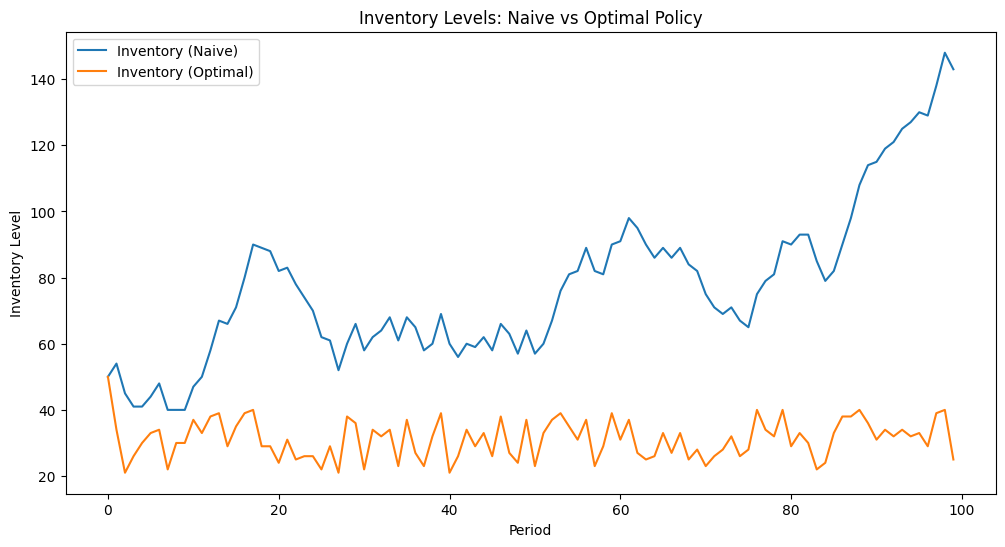

In [ ]:
# ============================
# Visualization
# ============================
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.plot(inv_naive, label='Inventory (Naive)')
plt.plot(inv_opt, label='Inventory (Optimal)')
plt.xlabel('Period')
plt.ylabel('Inventory Level')
plt.title('Inventory Levels: Naive vs Optimal Policy')
plt.legend()
plt.show()

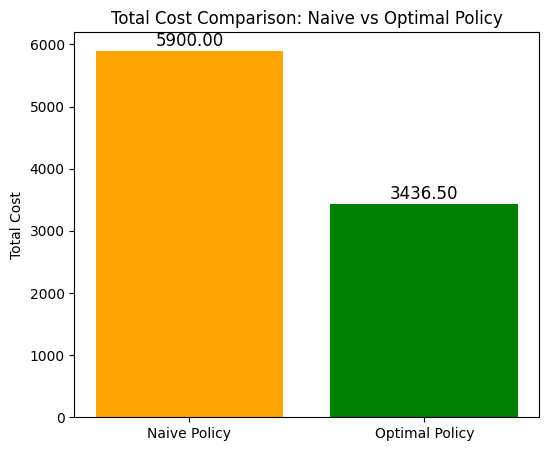

In [ ]:
# ============================
# Visualization: Total Cost (Single Run)
# ============================
import matplotlib.pyplot as plt

policies = ['Naive Policy', 'Optimal Policy']
total_costs = [cost_naive, cost_opt]

plt.figure(figsize=(6,5))
plt.bar(policies, total_costs, color=['orange', 'green'])
plt.ylabel('Total Cost')
plt.title('Total Cost Comparison: Naive vs Optimal Policy')

# Annotate bars with values
for i, cost in enumerate(total_costs):
    plt.text(i, cost + 5, f"{cost:.2f}", ha='center', va='bottom', fontsize=12)

plt.show()
